Classification Model Comparison
    Algorithm  Accuracy  Precision  Recall  F1-Score  Log Loss
          SVM    0.9667     0.9697  0.9667    0.9666    0.1125
Decision Tree    0.9333     0.9333  0.9333    0.9333    2.4029
          KNN    0.9333     0.9444  0.9333    0.9327    0.1196
  Naive Bayes    0.9667     0.9697  0.9667    0.9666    0.1420


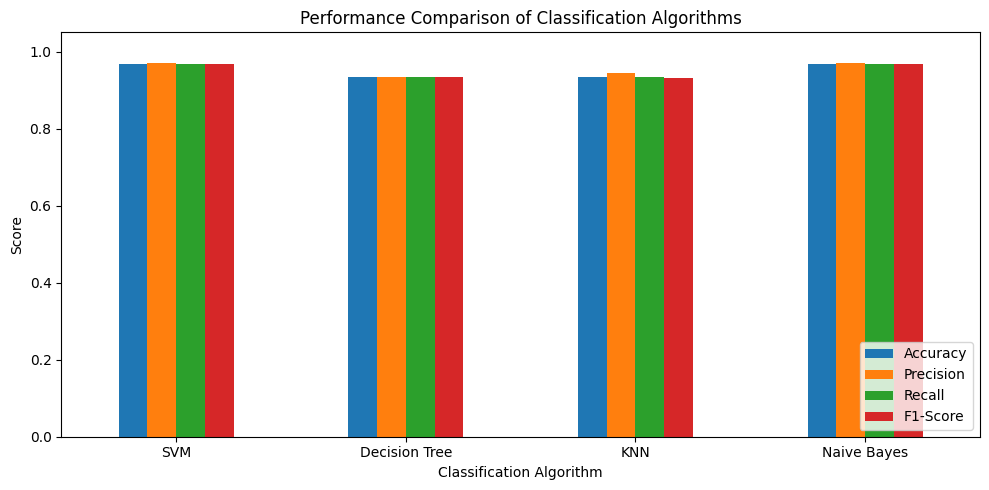

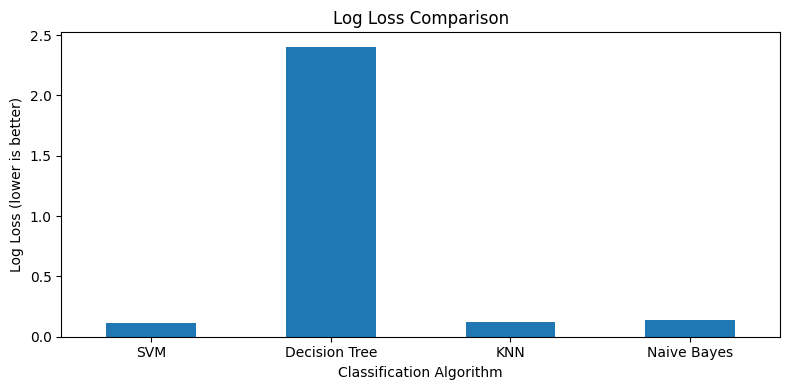

In [1]:
# AIML Assignment: Comparison of Classification Algorithms

# Import required libraries
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss
)

# 1. Load the Iris dataset
iris = load_iris()
X = iris.data
y = iris.target

# 2. Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 3. Define the classification models
models = {
    "SVM": make_pipeline(
        StandardScaler(),
        SVC(probability=True, random_state=42)
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    "Naive Bayes": GaussianNB()
}

# 4. Train and evaluate each model
results = []

for name, model in models.items():

    # Train the model
    model.fit(X_train, y_train)

    # Predict the class labels
    y_pred = model.predict(X_test)

    # Predict class probabilities
    y_prob = model.predict_proba(X_test)

    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, average="macro", zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, average="macro", zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, average="macro", zero_division=0
    )
    loss = log_loss(y_test, y_prob, labels=[0, 1, 2])

    results.append({
        "Algorithm": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "Log Loss": loss
    })

# 5. Display the comparison table
results_df = pd.DataFrame(results)

print("Classification Model Comparison")
print(results_df.round(4).to_string(index=False))

# 6. Plot the comparison of performance metrics
results_df.set_index("Algorithm")[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
].plot(kind="bar", figsize=(10, 5))

plt.title("Performance Comparison of Classification Algorithms")
plt.ylabel("Score")
plt.xlabel("Classification Algorithm")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# 7. Plot log loss separately
results_df.plot(
    x="Algorithm",
    y="Log Loss",
    kind="bar",
    legend=False,
    figsize=(8, 4)
)

plt.title("Log Loss Comparison")
plt.ylabel("Log Loss (lower is better)")
plt.xlabel("Classification Algorithm")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()